# Analisis performa regional — ETHICS

Penyelarasan gender/religion, 6 Oktober 2026. Akurasi Commonsense/Justice per subset bersama coverage; Deontology/Virtue memakai distribusi jawaban. Tabel beku dan p-value tidak berubah.

## Konsistensi dan batas interpretasi

N/E/I1–I3, nama model dan wilayah konsisten. Warna identitas berbeda dari warna status. Rerata I1–I3 hanya deskriptif. Bintang selalu keputusan Holm sumber, bukan ukuran efek besar. Arah sesuai urutan dalam label; tidak dibalik mengikuti urutan legend. Grafik gabungan lama diarsipkan, bukan dihapus.

## 1. SPEC dan DESIGN PLAN

Seluruh tabel eksperimen 1.514 soal × enam model × 17 skenario, empat subset. Tidak ada API/parsing/uji ulang. Render staging baru, periksa angka, arsipkan gambar lama, pasang PNG. Rencana: `docs/PENYELARASAN_AKURASI_REGIONAL_GENDER_RELIGION_2026-10-06.md`.

In [1]:
BENCHMARK="ETHICS"
FOLDER="ethics accuracy analysis"
NOTEBOOK_NAME="ETHICS_Regional_Cultural_Accuracy_Analysis_Lengkap.ipynb"
from pathlib import Path
from datetime import datetime
import ast, hashlib, json, re, shutil, sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.text import Text
from matplotlib.collections import PathCollection
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p/'AGENTS.md').is_file())
sys.path.insert(0,str(ROOT))
sys.path.insert(0,str(ROOT/'src/pipelines/analysis'))
ACTIVE = ROOT/'notebooks/regional'/FOLDER
TABLE_DIR = (ROOT/'result/benchmarks/gsm8k/reports/persona_publication_analysis_v5_paired_significance_six_models_bar3_compact_smalllabels_heatmap3_sigbold/tables') if BENCHMARK=='GSM8K' else ACTIVE/'tables'
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
RUN = ROOT/'result/analyses/accuracy/runs'/('regional_'+BENCHMARK.lower()+'_presentation_'+RUN_ID)
FIGURE_DIR = RUN/'figures'
FIGURE_DIR.mkdir(parents=True,exist_ok=False)
def file_hash(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
TABLE_HASHES = {str(p.resolve()):file_hash(p) for p in TABLE_DIR.glob('*.csv')}
LEGACY_STEMS = {'01_ethics_regional_absolute_accuracy_nine_categories','02_ethics_regional_delta_vs_neutral','03_ethics_regional_delta_implicit_vs_explicit','06_ethics_regional_effect_holm_heatmap','07_ethics_regional_exact_mcnemar_and_holm_pvalue_heatmap_part1','07_ethics_regional_exact_mcnemar_and_holm_pvalue_heatmap_part2','08_ethics_regional_combined_effect_holm_heatmap','09_ethics_regional_combined_exact_mcnemar_and_holm_pvalue_heatmap_part1','09_ethics_regional_combined_exact_mcnemar_and_holm_pvalue_heatmap_part2'}
MODEL_SOURCE = ['Qwen3 Next 80B-A3B','Llama 3.1 8B','Ministral 8B','DeepSeek R1-Distill 32B','GPT-OSS 20B','Llama 3.3 70B']
IDENTITIES = ['north_american','east_asian','south_asian','sub_saharan_african']
IL = dict(zip(IDENTITIES,['Amerika Utara','Asia Timur','Asia Selatan','Afrika Sub-Sahara']))
EN = dict(zip(IDENTITIES,['North American','East Asian','South Asian','Sub-Saharan African']))
PERSONAS = [i+'_'+c for i in IDENTITIES for c in ['explicit','implicit_1','implicit_2','implicit_3']]+['neutral']
PERSONA_LABELS = [IL[i]+' '+c for i in IDENTITIES for c in ['E','I1','I2','I3']]+['Neutral']
CATEGORIES = [IL[i]+' '+c for i in IDENTITIES for c in ['Explicit','Implicit Avg']]+['Neutral']
COLORS = ['#0047AB','#0086A8','#B80F2E','#E45700','#007A4D','#66A61E','#5B21B6','#A0006D','#30343B']
BACKGROUND = '#FCFBF8'
FONT_SIZES = dict(title=30,panel=26,axis=22,colorbar=25,cell=26)
RENDER_AUDIT = []
def display_label(value):
    s=str(value).replace('80B-A3B','80B')
    for old,new in [('DeepSeek R1-Distill','DeepSeek R1'),('Qwen3 Next 80B-A3B','Qwen3 Next 80B'),('North American','Amerika Utara'),('East Asian','Asia Timur'),('South Asian','Asia Selatan'),('Sub-Saharan African','Afrika Sub-Sahara'),('Regional Persona & Baseline','Persona regional dan skenario netral'),('Regional Cultural','Regional-Kultural'),('Global Neutral Avg','Rerata N enam model'),('Neutral Avg','Rerata N'),('Implicit Avg','Rerata I1–I3'),('Explicit','E'),('Implicit','I'),('Neutral','N'),('Accuracy','Akurasi'),('Difference on accuracy scale','Delta akurasi (skala 0–1)')]:
        s=s.replace(old,new)
    return s
def plot_values(fig):
    values=[]
    for ax in fig.axes:
        values += [np.array(line.get_xydata(),copy=True) for line in ax.lines]
        values += [np.array([p.get_x(),p.get_y(),p.get_width(),p.get_height()]) for p in ax.patches if hasattr(p,'get_height')]
        values += [np.array(c.get_array(),copy=True) for c in ax.collections if c.get_array() is not None]
    return values
def format_figure(fig):
    before=plot_values(fig)
    for ax in fig.axes:
        xlim,ylim=ax.get_xlim(),ax.get_ylim()
        for name in ['x','y']:
            texts=getattr(ax,'get_'+name+'ticklabels')()
            if any(display_label(t.get_text())!=t.get_text() for t in texts):
                getattr(ax,'set_'+name+'ticks')(getattr(ax,'get_'+name+'ticks')(),[display_label(t.get_text()) for t in texts])
        ax.set_xlim(xlim);ax.set_ylim(ylim)
        ax.title.set_fontweight('bold')
        for p in ax.patches:
            if hasattr(p,'get_height'): p.set_alpha(1)
        for c in ax.collections:
            if isinstance(c,PathCollection): c.set_alpha(1)
    for ax in fig.axes:
        for collection in ax.collections:
            a=collection.get_array()
            if a is not None and np.ndim(a)==2:
                for y,x in np.argwhere(np.ma.getmaskarray(a)):
                    ax.text(x+.5,y+.5,'NA',ha='center',va='center',fontsize=12,color='#17212B')
    for t in fig.findobj(Text): t.set_text(display_label(t.get_text()))
    if fig._suptitle: fig._suptitle.set_fontweight('bold')
    after=plot_values(fig)
    assert len(before)==len(after)
    assert all(np.array_equal(a,b,equal_nan=True) for a,b in zip(before,after))
    return len(before)
def save_plot(fig,stem,detail=''):
    arrays=format_figure(fig)
    path=FIGURE_DIR/(stem+'.png')
    assert not path.exists(),path
    fig.savefig(path,dpi=220,facecolor=BACKGROUND,bbox_inches='tight',pad_inches=.25)
    plt.close(fig)
    RENDER_AUDIT.append(dict(file=path.name,numeric_arrays_unchanged=arrays,detail=detail))
    print('PNG:',path.name,flush=True)
    return path
def show_figure(name,width=1300):
    if not name.endswith('.png'): name+='.png'
    display(Image(filename=str(ACTIVE/'figures'/name),width=width))
def publish():
    assert all(file_hash(p)==h for p,h in TABLE_HASHES.items())
    # Preserve PNG types not regenerated; invalid pooled accuracy remains in the archive.
    for p in (ACTIVE/'figures').glob('*.png'):
        if p.stem not in LEGACY_STEMS and not (FIGURE_DIR/p.name).exists():
            shutil.copy2(p,FIGURE_DIR/p.name)
    assert not list(FIGURE_DIR.glob('*.svg'))
    for p in FIGURE_DIR.glob('*.png'):
        with PILImage.open(p) as im: im.verify()
    archive=ACTIVE/'_arsip'/('accuracy_before_'+RUN_ID)
    archive.mkdir(parents=True,exist_ok=False)
    for target in [ACTIVE/'figures',archive]:
        assert target.resolve().is_relative_to((ROOT/'notebooks/regional').resolve())
    old={str(p.relative_to(ACTIVE/'figures')):file_hash(p) for p in (ACTIVE/'figures').rglob('*') if p.is_file()}
    shutil.move(str(ACTIVE/'figures'),str(archive/'figures'))
    assert old=={str(p.relative_to(archive/'figures')):file_hash(p) for p in (archive/'figures').rglob('*') if p.is_file()}
    for name in ['README.md','LATEST_RUN.json','output_index.csv','active_figures.csv','presentation_manifest.json','bundle_manifest.json']:
        if (ACTIVE/name).exists(): shutil.copy2(ACTIVE/name,archive/name)
    shutil.copy2(ACTIVE/NOTEBOOK_NAME,archive/NOTEBOOK_NAME)
    shutil.copytree(FIGURE_DIR,ACTIVE/'figures')
    index=pd.DataFrame([dict(kind='figure',file=p.name,relative_path='figures/'+p.name,path=str(ACTIVE/'figures'/p.name),sha256=file_hash(p),status='regenerated' if p.name in {r['file'] for r in RENDER_AUDIT} else 'preserved_supporting_png') for p in sorted(FIGURE_DIR.glob('*.png'))])
    index.to_csv(RUN/'figure_index.csv',index=False)
    index.to_csv(ACTIVE/'output_index.csv',index=False)
    index.rename(columns={'relative_path':'figure'}).to_csv(ACTIVE/'active_figures.csv',index=False)
    manifest=dict(benchmark=BENCHMARK,run=str(RUN),archive=str(archive),source_table_hashes=TABLE_HASHES,rendered=RENDER_AUDIT,png=len(index),svg=0,new_tests=False,rescoring=False,api_calls=0,latex_changed=False,legacy_accuracy_figures_archived=sorted(LEGACY_STEMS) if BENCHMARK=='ETHICS' else [])
    (RUN/'presentation_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    (ACTIVE/'presentation_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    (ACTIVE/'LATEST_RUN.json').write_text(json.dumps({'run':str(RUN),'archive':str(archive)},indent=2),encoding='utf-8')
    (archive/'preserved_hashes.json').write_text(json.dumps(old,indent=2),encoding='utf-8')
    assert all(file_hash(ACTIVE/'figures'/r['file'])==r['sha256'] for r in index.to_dict('records'))
    print('PUBLISH_OK',BENCHMARK,len(index),'PNG; sumber statistik tidak berubah.',flush=True)
    return manifest
sns.set_theme(style='whitegrid',font='DejaVu Sans')
plt.rcParams.update({'figure.facecolor':BACKGROUND,'axes.facecolor':BACKGROUND,'axes.titleweight':'bold','font.size':14,'axes.titlesize':23,'axes.labelsize':18,'xtick.labelsize':14,'ytick.labelsize':14,'legend.fontsize':13})

EXPECTED_TABLE_HASHES = {
  "ethics_abstain_reasons_by_model.csv": "9503aec07c2e4f51f6128d3ece32ab9e1a6e9a072e5790866551e9fc1d9cc366",
  "ethics_abstain_reasons_by_model_persona_category.csv": "8859e03b2820eab92ea4c230399110151c4c168eef30537a8acffa9fff48cb54",
  "ethics_accuracy_by_model_persona_category.csv": "d8794ea9fdefece2db3b931a34fddfb3c002bb95fe28b8233bdc06a4303c9159",
  "ethics_accuracy_inference_construct_valid.csv": "011ea80d7a4904637c73afb93fa9bd2665603ea3df3a40263b557f2345989ca2",
  "ethics_accuracy_inference_construct_valid_combined.csv": "ff4d87d40b34b7fd0cf2c7a4ded2c917195e0e2dda55d33be759909414f98059",
  "ethics_accuracy_source_v3.csv": "7d58c23eb6e4f8bf35beb839f30dae7ed2c036899cfc7c596b371ccb3e2df193",
  "ethics_cochran_q.csv": "2410f357b5e4f457e0046917fe3e9cbc59bdbe4af1280ad88eb39d8856fb05c3",
  "ethics_condition_summary_source_derived.csv": "f0cf9abe6315fb234fe826d4219cd0c4a6e25b0ceff38e9333ba4c71b4f50b11",
  "ethics_paired_effects_all.csv": "d95b940d89c5ba6db4798b6db184d7475a1681bb4d0b5d35e72d3a545412c270",
  "ethics_paired_effects_regional.csv": "c7c59e24f326a4cf428e13b97823d77edf2d964d998508ce8327864a660d5c28",
  "ethics_paired_effects_scenario.csv": "c77e904aa6665032e8f40875bce637a14988cd4544e9864adecc2a770a4d26f2",
  "ethics_regional_completion_token_accuracy_tradeoff_implicit_vs_explicit.csv": "d7a7f9f91ca79fd7832c9979a2e0ed04fb4217de60d9af6ed29aa423120e665c",
  "ethics_regional_completion_token_category_summary.csv": "8f2e07e8813ba24e1f330e95b4e453e2a707e8245589e868e274b1546854a64c",
  "ethics_regional_completion_token_delta_vs_neutral_pct.csv": "cb596a85d790699007efeb290dbd1b87f6dc552d3582a3b050233fcc763a8bdf",
  "ethics_regional_parity_abstain_reasons.csv": "d46158d8e9ba3e1cd38a8dac3d2c1fa61e0f992f2df58750255010fce9b80cea",
  "ethics_regional_parity_all_subset_summary.csv": "14fcc2d89b219265ce85193d8650b10233cd8d81e45c40121979cfbead01c253",
  "ethics_regional_parity_category_summary.csv": "cc38912a5af603ad852ee779b9fa63a01bca81a2b1271df4151d02b5ea453a6d",
  "ethics_regional_parity_condition_summary.csv": "8bf1f531a69314eff421e8c927a26a86bdaab18d7d92bbe86a51c79aff9acd8c",
  "ethics_regional_parity_cramers_v.csv": "a053e516266afcdf22b78f08771cd6e3f89066c63cd17ae6f1da4c78be780b70",
  "ethics_regional_parity_paired_effects_vs_neutral.csv": "7dd65a0ab5ff2dc4753b5edddaf72f0637acee2b274fcc771d45dd5c6f799359",
  "ethics_status_by_model_persona_category.csv": "bf5ffaf2ea24719f36503d4be3fb4411168278f785b45220e0c585fee431fbce"
}
assert all(file_hash(TABLE_DIR/name)==digest for name,digest in EXPECTED_TABLE_HASHES.items())


### Penyajian

Akurasi dan inferensi utama per subset Commonsense/Justice. Status seluruh subset; distribusi wrong/acceptable Deontology/Virtue. Gabungan stance/status hanya deskriptif berbobot respons. Tiga grafik token dipertahankan sebagai pendukung historis.

## 2. CHECKLIST — validasi tabel sumber

In [2]:
summary=pd.read_csv(TABLE_DIR/'ethics_condition_summary_source_derived.csv')
parity_summary=pd.read_csv(TABLE_DIR/'ethics_regional_parity_condition_summary.csv')
paired_all=pd.read_csv(TABLE_DIR/'ethics_paired_effects_all.csv')
combined=pd.read_csv(TABLE_DIR/'ethics_regional_parity_category_summary.csv')
status=pd.read_csv(TABLE_DIR/'ethics_status_by_model_persona_category.csv')
assert len(summary)==408 and int(summary.total.sum())==154428
assert {c:int(summary[c].sum()) for c in ['committed','abstain','missing']}=={'committed':112035,'abstain':40570,'missing':1823}
assert not summary.duplicated(['model','persona','subset']).any()
assert summary.total.eq(summary.committed+summary.abstain+summary.missing).all()
assert summary.n_answer_wrong.add(summary.n_answer_acceptable).eq(summary.committed).all()
assert np.allclose(summary.accuracy_committed,summary.n_correct/summary.committed,equal_nan=True)
joined=summary.merge(parity_summary,on=['model','persona','subset'],suffixes=('_old','_parity'),validate='one_to_one')
for c in ['total','committed','abstain','missing','n_answer_wrong','n_answer_acceptable']:
    assert np.allclose(joined[c+'_old'],joined[c+'_parity'],equal_nan=True),c
valid=joined.subset.isin(['commonsense','justice'])
assert np.allclose(joined.loc[valid,'n_correct_old'],joined.loc[valid,'n_correct_parity'],equal_nan=True)
assert joined.loc[~valid,'n_correct_parity'].isna().all()
assert len(paired_all)==1248 and paired_all.groupby(['subset','model']).size().eq(52).all()
assert paired_all.holm_family_size.value_counts().to_dict()=={7:672,24:576}
assert np.allclose(paired_all.delta_accuracy_pp,paired_all.accuracy_a_pct-paired_all.accuracy_b_pct)
h=2*np.arcsin(np.sqrt(paired_all.accuracy_a_pct/100))-2*np.arcsin(np.sqrt(paired_all.accuracy_b_pct/100))
assert np.allclose(h,paired_all.cohens_h)
assert paired_all.significant_holm_0_05.eq(paired_all.holm_adjusted_p_value.lt(.05)).all()
assert np.allclose(summary.commit_rate,summary.committed/summary.total)
assert len(combined)==54 and combined.subset.eq('all').all()
category_map={EN[i]+' '+c:IL[i]+' '+c for i in IDENTITIES for c in ['Explicit','Implicit Avg']}
combined['category']=combined.category_label.replace(category_map)
summary['category']=summary.category.replace(category_map)
status['category']=status.category.replace(category_map)
assert set(combined.category)==set(CATEGORIES)==set(summary.category)==set(status.category)
print('VALIDATION_OK: 154428 respons; 408 ringkasan; 1248 kontras; tanpa uji ulang.')


VALIDATION_OK: 154428 respons; 408 ringkasan; 1248 kontras; tanpa uji ulang.


## 3. Tabel sumber per subset

Seluruh respons tetap masuk total. Akurasi committed selalu disertai commit rate, abstain dan missing. Dua subset tidak dipromosikan sebagai akurasi moral.

In [3]:
for subset in ['commonsense','deontology','justice','virtue']:
    columns=['model_label','persona','total','committed','commit_rate','abstain','abstain_rate','missing','missing_rate']
    columns+=['n_correct','accuracy_committed'] if subset in ['commonsense','justice'] else ['n_answer_wrong','n_answer_acceptable','pct_answer_wrong','pct_answer_acceptable']
    display(Markdown('### '+subset.title()))
    display(summary[summary.subset.eq(subset)][columns])


### Commonsense

,model_label,persona,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_correct,accuracy_committed
0,DeepSeek R1-Distill 32B,east_asian_explicit,388,326,0.840206,62,0.159794,0,0.000000,203,0.622699
4,DeepSeek R1-Distill 32B,east_asian_implicit_1,388,153,0.394330,227,0.585052,8,0.020619,118,0.771242
8,DeepSeek R1-Distill 32B,east_asian_implicit_2,388,231,0.595361,156,0.402062,1,0.002577,172,0.744589
12,DeepSeek R1-Distill 32B,east_asian_implicit_3,388,171,0.440722,212,0.546392,5,0.012887,135,0.789474
16,DeepSeek R1-Distill 32B,neutral,388,241,0.621134,145,0.373711,2,0.005155,143,0.593361
...,...,...,...,...,...,...,...,...,...,...,...
388,Qwen3 Next 80B-A3B,south_asian_implicit_3,388,331,0.853093,52,0.134021,5,0.012887,192,0.580060
392,Qwen3 Next 80B-A3B,sub_saharan_african_explicit,388,376,0.969072,3,0.007732,9,0.023196,236,0.627660
396,Qwen3 Next 80B-A3B,sub_saharan_african_implicit_1,388,347,0.894330,38,0.097938,3,0.007732,202,0.582133
400,Qwen3 Next 80B-A3B,sub_saharan_african_implicit_2,388,337,0.868557,48,0.123711,3,0.007732,203,0.602374


### Deontology

,model_label,persona,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_answer_wrong,n_answer_acceptable,pct_answer_wrong,pct_answer_acceptable
1,DeepSeek R1-Distill 32B,east_asian_explicit,359,196,0.545961,162,0.451253,1,0.002786,87,109,0.443878,0.556122
5,DeepSeek R1-Distill 32B,east_asian_implicit_1,359,123,0.342618,215,0.598886,21,0.058496,17,106,0.138211,0.861789
9,DeepSeek R1-Distill 32B,east_asian_implicit_2,359,197,0.548747,162,0.451253,0,0.000000,73,124,0.370558,0.629442
13,DeepSeek R1-Distill 32B,east_asian_implicit_3,359,198,0.551532,149,0.415042,12,0.033426,36,162,0.181818,0.818182
17,DeepSeek R1-Distill 32B,neutral,359,214,0.596100,142,0.395543,3,0.008357,74,140,0.345794,0.654206
...,...,...,...,...,...,...,...,...,...,...,...,...,...
389,Qwen3 Next 80B-A3B,south_asian_implicit_3,359,232,0.646240,124,0.345404,3,0.008357,200,32,0.862069,0.137931
393,Qwen3 Next 80B-A3B,sub_saharan_african_explicit,359,343,0.955432,16,0.044568,0,0.000000,164,179,0.478134,0.521866
397,Qwen3 Next 80B-A3B,sub_saharan_african_implicit_1,359,211,0.587744,148,0.412256,0,0.000000,186,25,0.881517,0.118483
401,Qwen3 Next 80B-A3B,sub_saharan_african_implicit_2,359,192,0.534819,167,0.465181,0,0.000000,159,33,0.828125,0.171875


### Justice

,model_label,persona,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_correct,accuracy_committed
2,DeepSeek R1-Distill 32B,east_asian_explicit,270,227,0.840741,42,0.155556,1,0.003704,155,0.682819
6,DeepSeek R1-Distill 32B,east_asian_implicit_1,270,70,0.259259,193,0.714815,7,0.025926,62,0.885714
10,DeepSeek R1-Distill 32B,east_asian_implicit_2,270,229,0.848148,41,0.151852,0,0.000000,174,0.759825
14,DeepSeek R1-Distill 32B,east_asian_implicit_3,270,79,0.292593,186,0.688889,5,0.018519,70,0.886076
18,DeepSeek R1-Distill 32B,neutral,270,190,0.703704,78,0.288889,2,0.007407,135,0.710526
...,...,...,...,...,...,...,...,...,...,...,...
390,Qwen3 Next 80B-A3B,south_asian_implicit_3,270,211,0.781481,58,0.214815,1,0.003704,160,0.758294
394,Qwen3 Next 80B-A3B,sub_saharan_african_explicit,270,265,0.981481,4,0.014815,1,0.003704,216,0.815094
398,Qwen3 Next 80B-A3B,sub_saharan_african_implicit_1,270,236,0.874074,31,0.114815,3,0.011111,176,0.745763
402,Qwen3 Next 80B-A3B,sub_saharan_african_implicit_2,270,247,0.914815,22,0.081481,1,0.003704,184,0.744939


### Virtue

,model_label,persona,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_answer_wrong,n_answer_acceptable,pct_answer_wrong,pct_answer_acceptable
3,DeepSeek R1-Distill 32B,east_asian_explicit,497,464,0.933602,33,0.066398,0,0.000000,358,106,0.771552,0.228448
7,DeepSeek R1-Distill 32B,east_asian_implicit_1,497,237,0.476861,251,0.505030,9,0.018109,146,91,0.616034,0.383966
11,DeepSeek R1-Distill 32B,east_asian_implicit_2,497,321,0.645875,174,0.350101,2,0.004024,225,96,0.700935,0.299065
15,DeepSeek R1-Distill 32B,east_asian_implicit_3,497,268,0.539235,220,0.442656,9,0.018109,170,98,0.634328,0.365672
19,DeepSeek R1-Distill 32B,neutral,497,330,0.663984,164,0.329980,3,0.006036,211,119,0.639394,0.360606
...,...,...,...,...,...,...,...,...,...,...,...,...,...
391,Qwen3 Next 80B-A3B,south_asian_implicit_3,497,363,0.730382,130,0.261569,4,0.008048,247,116,0.680441,0.319559
395,Qwen3 Next 80B-A3B,sub_saharan_african_explicit,497,478,0.961771,1,0.002012,18,0.036217,340,138,0.711297,0.288703
399,Qwen3 Next 80B-A3B,sub_saharan_african_implicit_1,497,405,0.814889,90,0.181087,2,0.004024,298,107,0.735802,0.264198
403,Qwen3 Next 80B-A3B,sub_saharan_african_implicit_2,497,397,0.798793,97,0.195171,3,0.006036,281,116,0.707809,0.292191


## 4. IMPLEMENTATION — fungsi render notebook

In [4]:
def category_plot(frame,metric,ax,ylabel):
    values=frame.pivot(index='model_label',columns='category',values=metric).reindex(index=MODEL_SOURCE,columns=CATEGORIES)
    values.plot(kind='bar',width=.86,color=COLORS,ax=ax)
    ax.set_ylabel(ylabel);ax.set_xlabel('Model');ax.tick_params(axis='x',rotation=0,labelsize=12)
    ax.set_ylim(0,1.08);ax.legend(loc='upper left',bbox_to_anchor=(1.01,1),fontsize=11)
    return values
def render_stance_status_and_subsets():
    from dataclasses import replace
    from src.benchmarks.ethics import build_ethics_domain_accuracy_parity_v1 as parity
    config=replace(parity.CONFIGS['regional'],identities=tuple((i,IL[i],IL[i]) for i in IDENTITIES))
    old=parity.save_figure
    def parity_save(fig,directory,stem,overwrite):
        before=plot_values(fig)
        number=stem.split('_')[0]
        if number in ['02','03']:
            n=3 if number=='02' else 4
            fig.set_size_inches(36,9.5*n)
            height=(.87-.075*(n-1))/n
            for i,ax in enumerate(fig.axes[:n]):
                ax.set_position([.17,.94-(i+1)*height-i*.075,.74,height])
                ax.tick_params(axis='both',labelbottom=True,labelleft=True,labelsize=22)
                ax.set_xticks(np.arange(17)+.5,[display_label(p) for p in PERSONA_LABELS],rotation=35,ha='right')
                ax.set_yticks(np.arange(6)+.5,[display_label(m) for m in MODEL_SOURCE],rotation=0)
                ax.title.set_fontsize(26)
                for t in ax.texts: t.set_fontsize(26)
            fig.axes[-1].set_position([.94,.15,.012,.67])
        elif number in ['04','05']:
            n=6
            fig.set_size_inches(44,30)
            reason_labels={'Analysis without verdict':'Analisis tanpa verdict','No-opinion stop':'Berhenti tanpa opini','Both sides':'Dua sisi jawaban','Task substitution':'Penggantian tugas','Explicit binary refusal':'Penolakan biner eksplisit','Insufficient context':'Konteks tidak cukup','AI refusal':'Penolakan sebagai AI','Placeholder confusion':'Kebingungan placeholder','Returns question':'Mengembalikan pertanyaan','Conditional only':'Hanya kondisional','Capability mismatch':'Ketidakcocokan kemampuan','Detector disagreement':'Ketidaksepakatan detektor'}
            for i,ax in enumerate(fig.axes[:n]):
                ax.set_position([.12+.48*(i%2),.71-.30*(i//2),.32,.23])
                ax.tick_params(axis='both',labelbottom=True,labelleft=True,labelsize=15)
                ax.set_xticks(np.arange(17)+.5,[display_label(p) for p in PERSONA_LABELS],rotation=40,ha='right')
                ax.set_yticks(ax.get_yticks(),[{k.casefold():v for k,v in reason_labels.items()}.get(t.get_text().casefold(),t.get_text()) for t in ax.get_yticklabels()],rotation=0)
                ax.set_ylabel('');ax.title.set_fontsize(23)
                for t in ax.texts: t.set_fontsize(15)
            fig.axes[-1].set_position([.95,.17,.008,.66])
        else:
            n=0
            for t in fig.findobj(Text):
                if t is not fig._suptitle and t not in [ax.title for ax in fig.axes]: t.set_fontsize(t.get_fontsize()+4)
        if n:
            fig._suptitle.set_position((.5,.985));fig._suptitle.set_fontsize(30)
            for t in fig.texts:
                if t is not fig._suptitle: t.set_position((.5,.018));t.set_fontsize(18)
            fig.canvas.draw()
            canvas_renderer=fig.canvas.get_renderer()
            for ax in fig.axes[:n]:
                cell_width=ax.get_window_extent(canvas_renderer).width/17
                assert all(t.get_window_extent(canvas_renderer).width<cell_width*.95 for t in ax.texts),'Annotation exceeds cell width'
        after=plot_values(fig)
        assert len(before)==len(after) and all(np.array_equal(a,b,equal_nan=True) for a,b in zip(before,after))
        return {'png':str(save_plot(fig,stem,'Status/coverage/alasan dari tabel beku'))}
    parity.save_figure=parity_save
    try:
        all_summary=pd.read_csv(TABLE_DIR/'ethics_regional_parity_all_subset_summary.csv')
        reasons=pd.read_csv(TABLE_DIR/'ethics_regional_parity_abstain_reasons.csv')
        parity.plot_status_heatmaps(all_summary,config,FIGURE_DIR,False)
        parity.plot_commit_rate_by_subset(summary,config,FIGURE_DIR,False)
        for metric,num,title in [('pct_of_abstain','04','Alasan di antara abstain'),('pct_of_nonmissing','05','Prevalensi alasan abstain')]:
            parity.plot_reason_heatmaps(reasons,config,FIGURE_DIR,False,metric=metric,stem_number=num,title=title,metric_label='Denominator: '+('abstain' if num=='04' else 'non-missing'))
        parity.plot_cramers_v(pd.read_csv(TABLE_DIR/'ethics_regional_parity_cramers_v.csv'),config,FIGURE_DIR,False)
    finally:
        parity.save_figure=old
    # All-subset stance and status are descriptive, not accuracy.
    for frame,stem,columns,labels in [
       (combined,'00_ethics_regional_combined_four_subsets_distribution',['pct_answer_wrong','pct_answer_acceptable'],['Wrong','Acceptable']),
       (status,'01_ethics_regional_status_composition_by_model',['commit_rate','abstain_rate','missing_rate'],['Committed','Abstain','Missing'])]:
        fig,axes=plt.subplots(2,3,figsize=(32,16),layout='constrained')
        for ax,model in zip(axes.flat,MODEL_SOURCE):
            data=frame[frame.model_label.eq(model)].set_index('category').reindex(CATEGORIES)
            bottom=np.zeros(9)
            for col,label,color in zip(columns,labels,['#2463EB','#D59000','#89939F']):
                ax.bar(np.arange(9),data[col],bottom=bottom,label=label,color=color);bottom+=data[col].to_numpy()
            ax.set_xticks(np.arange(9),[display_label(c).replace('Rerata I1–I3','I rata-rata') for c in CATEGORIES],rotation=45,ha='right')
            ax.set_ylim(0,1);ax.set_title(model,fontweight='bold');ax.legend(fontsize=11)
        fig.suptitle('ETHICS · Persona regional: '+('distribusi jawaban committed' if len(columns)==2 else 'status respons')+' — gabungan deskriptif',fontsize=23,fontweight='bold')
        fig.supxlabel('Berbobot jumlah respons tersedia; bukan akurasi gabungan. I rata-rata menggabungkan I1–I3.',fontsize=13)
        save_plot(fig,stem,'Gabungan deskriptif; bukan skor moral')
    matrix=combined.pivot(index='model_label',columns='category',values='pct_answer_wrong').reindex(MODEL_SOURCE)
    for implicit,stem in [(False,'00_ethics_regional_combined_delta_vs_neutral'),(True,'00_ethics_regional_combined_delta_implicit_explicit')]:
        if implicit:
            delta=pd.DataFrame({IL[i]+': rerata I1–I3 − E':matrix[IL[i]+' Implicit Avg']-matrix[IL[i]+' Explicit'] for i in IDENTITIES})
            colors=COLORS[::2][:-1]
        else:
            delta=pd.DataFrame({c+' − N':matrix[c]-matrix['Neutral'] for c in CATEGORIES[:-1]});colors=COLORS[:-1]
        fig,ax=plt.subplots(figsize=(32,10));(delta*100).plot.bar(ax=ax,color=colors,width=.85)
        ax.axhline(0,color='black');ax.set_ylabel('Delta proporsi wrong (poin persentase)');ax.set_xlabel('Model');ax.tick_params(axis='x',rotation=0)
        ax.set_title('ETHICS · Persona regional: delta distribusi jawaban — '+('I − E' if implicit else 'persona − N'),fontsize=23,fontweight='bold')
        ax.legend(bbox_to_anchor=(1.01,1),loc='upper left',fontsize=12)
        fig.text(.5,-.02,'Deskriptif, berbobot committed; bukan delta akurasi dan bukan uji pasangan.',ha='center',fontsize=13)
        save_plot(fig,stem,'Nilai stance gabungan dari tabel; tanpa inferensi baru')
    counts=['total','committed','abstain','missing','n_correct','n_answer_wrong','n_answer_acceptable']
    for subset in ['commonsense','deontology','justice','virtue']:
        d=summary[summary.subset.eq(subset)].groupby(['model_label','category'],as_index=False)[counts].sum()
        assert d.total.eq(d.committed+d.abstain+d.missing).all()
        d['commit_rate']=d.committed/d.total
        valid=subset in ['commonsense','justice']
        d['performance']=(d.n_correct if valid else d.n_answer_wrong)/d.committed
        fig,axes=plt.subplots(2,1,figsize=(32,17),layout='constrained')
        category_plot(d,'performance',axes[0],'Akurasi committed' if valid else 'Proporsi wrong / committed')
        category_plot(d,'commit_rate',axes[1],'Commit rate')
        axes[0].set_title('Akurasi committed' if valid else 'Distribusi jawaban, bukan akurasi',fontweight='bold')
        axes[1].set_title('Coverage: committed / seluruh respons',fontweight='bold')
        fig.suptitle('ETHICS · Persona regional: '+subset.title(),fontsize=23,fontweight='bold')
        save_plot(fig,'01_'+subset+'_performance_by_persona','Akurasi hanya subset valid; coverage satu gambar')
        fig,axes=plt.subplots(2,3,figsize=(32,16),layout='constrained')
        for ax,model in zip(axes.flat,MODEL_SOURCE):
            part=d[d.model_label.eq(model)].set_index('category').reindex(CATEGORIES)
            bottom=np.zeros(9)
            for col,color in [('committed','#2463EB'),('abstain','#D59000'),('missing','#89939F')]:
                v=part[col]/part.total
                ax.bar(np.arange(9),v,bottom=bottom,color=color,label=col);bottom+=v
            ax.set_title(model,fontweight='bold');ax.set_ylim(0,1)
            ax.set_xticks(np.arange(9),[display_label(c).replace('Rerata I1–I3','I rata-rata') for c in CATEGORIES],rotation=45,ha='right')
            ax.legend(fontsize=11)
        fig.suptitle('ETHICS · Persona regional: status respons — '+subset.title(),fontsize=23,fontweight='bold')
        save_plot(fig,'02_'+subset+'_status_by_persona','Status per subset; tidak ada hasil dibuang')

def render_valid_subset_contrasts():
    for subset in ['commonsense','justice']:
        d=paired_all[paired_all.subset.eq(subset)].copy()
        lookup=d.drop_duplicates(['condition_a','condition_b']).set_index(['condition_a','condition_b']).comparison_label.to_dict()
        scenarios=['explicit','implicit_1','implicit_2','implicit_3']
        keys=[]
        for identity in IDENTITIES:
            keys.extend((identity+'_'+s,'neutral') for s in scenarios)
            keys.extend((identity+'_'+s,identity+'_explicit') for s in scenarios[1:])
        for i,a in enumerate(IDENTITIES):
            for b in IDENTITIES[i+1:]:
                keys.extend((a+'_'+s,b+'_'+s) for s in scenarios)
        keys=[key if key in lookup else (key[1],key[0]) for key in keys]
        assert len(keys)==52 and set(keys)==set(lookup)
        order=[lookup[key] for key in keys]
        assert len(order)==52
        sig=d.pivot(index='model_label',columns='comparison_label',values='significant_holm_0_05').reindex(index=MODEL_SOURCE,columns=order)
        for column,kind,title in [('cohens_h','effect_holm','Ukuran efek dan keputusan Holm'),('exact_mcnemar_p_value','exact_mcnemar','P-value Exact McNemar'),('holm_adjusted_p_value','holm_pvalue','P-value Holm')]:
            values=d.pivot(index='model_label',columns='comparison_label',values=column).reindex(index=MODEL_SOURCE,columns=order)
            fig,axes=plt.subplots(4,1,figsize=(32,27))
            bounds=[(0,14),(14,28),(28,40),(40,52)]
            limit=max(.1,float(values.abs().max().max())) if kind=='effect_holm' else .05
            panel_titles=['Amerika Utara dan Asia Timur: persona − N serta I − E','Asia Selatan dan Afrika Sub-Sahara: persona − N serta I − E','Amerika Utara dan kawasan lain (arah pada label)','Perbandingan antarkawasan lainnya']
            for ax,(start,stop),panel_title in zip(axes,bounds,panel_titles):
                block=values.iloc[:,start:stop]; stars=sig.iloc[:,start:stop]
                ann=np.array([[('NA' if pd.isna(v) else (f'{v:+.2f}' if kind=='effect_holm' else ('<0,001' if v<.001 else f'{v:.3f}')))+('*' if bool(s) else '') for v,s in zip(vr,sr)] for vr,sr in zip(block.to_numpy(),stars.to_numpy())])
                sns.heatmap(block,annot=ann,fmt='',cmap='RdBu_r' if kind=='effect_holm' else 'YlOrRd_r',vmin=-limit if kind=='effect_holm' else 0,vmax=limit,annot_kws={'fontsize':15},cbar_kws={'label':"Cohen's h (kiri − kanan)" if kind=='effect_holm' else 'p-value; warna dibatasi 0–0,05'},ax=ax)
                ax.set_xticklabels([display_label(c).replace(' − ','\n− ') for c in block.columns],rotation=35,ha='right',fontsize=12)
                ax.set_yticklabels(MODEL_SOURCE,rotation=0,fontsize=15);ax.set_xlabel('');ax.set_ylabel('')
                ax.set_title(panel_title,fontsize=19,fontweight='bold',pad=14)
                for t in ax.texts:t.set_fontweight('bold' if '*' in t.get_text() else 'normal')
            fig.suptitle('ETHICS · Persona regional: '+title+' — '+subset.title(),fontsize=25,fontweight='bold')
            fig.subplots_adjust(left=.15,right=.98,bottom=.12,top=.93,hspace=1.1)
            fig.text(.5,.035,'Seluruh pasangan soal; non-committed dihitung tidak benar pada tabel sumber. Berbeda dari akurasi committed.',ha='center',fontsize=13)
            fig.text(.5,.015,'* selalu p Holm <0,05 · keluarga 7/24 per model/subset · 52 kontras · baca bersama coverage per skenario.',ha='center',fontsize=13)
            save_plot(fig,'17_'+subset+'_regional_'+kind,'Kontras lengkap per subset valid; sumber A−B tanpa inversi')

def render_legacy_status_and_reasons():
    # Preserve these distinct presentation types with current labels and PNG export.
    from src.pipelines.analysis import render_ethics_regional_overall_standardized as legacy
    old=legacy._save
    def notebook_save(fig,directory,stem):
        return [save_plot(fig,stem,'Status/alasan dari tabel beku; format diperbarui')]
    legacy._save=notebook_save
    try:
        legacy.configure_plot_style()
        legacy.plot_status(pd.read_csv(TABLE_DIR/'ethics_status_by_model_persona_category.csv'),FIGURE_DIR)
        legacy.plot_abstain_reasons(pd.read_csv(TABLE_DIR/'ethics_abstain_reasons_by_model.csv'),FIGURE_DIR)
    finally:
        legacy._save=old


## 5. Render seluruh keluaran baru

Nilai plot dicek tidak berubah oleh pemformatan; lebar angka heatmap status/alasan dicek terhadap sel.

In [5]:
render_stance_status_and_subsets()
render_valid_subset_contrasts()
heatmap_notebook=ACTIVE/'ETHICS_Regional_Accuracy_Heatmap_06_13.ipynb'
heatmap_source='\n'.join(''.join(c['source']) for c in json.loads(heatmap_notebook.read_text(encoding='utf-8'))['cells'] if c['cell_type']=='code')
node=next(n for n in ast.parse(heatmap_source).body if isinstance(n,ast.FunctionDef) and n.name=='render_parity_heatmaps')
exec(compile(ast.Module(body=[node],type_ignores=[]),'heatmap-notebook-function','exec'))
render_parity_heatmaps()

render_legacy_status_and_reasons()


PNG: 02_ethics_regional_status_by_model_persona_heatmap.png


PNG: 03_ethics_regional_commit_rate_by_persona_subset_heatmap.png


PNG: 04_ethics_regional_abstain_reason_share_by_model_persona_heatmap.png


PNG: 05_ethics_regional_abstain_reason_prevalence_by_model_persona_heatmap.png


PNG: 09_ethics_regional_status_persona_cramers_v.png


...

PNG: 11_ethics_regional_conditional_accuracy_effect_holm_heatmap.png


PNG: 12_ethics_regional_effective_success_effect_holm_heatmap.png


PNG: 13_ethics_regional_stance_wrong_effect_holm_heatmap.png


PNG: 04_ethics_regional_status_by_model_persona.png


PNG: 05_ethics_regional_abstain_reasons_by_model.png


## 6. Publikasi PNG setelah pemeriksaan dan arsip

In [6]:
manifest=publish()
readme="""# Analisis performa persona regional — ETHICS
Penyelarasan 6 Oktober 2026 langsung dalam dua notebook yang ada. Buka notebook lengkap; notebook Heatmap_06_13 mereproduksi tujuh heatmap.
PNG aktif berada di figures/. Run terbaru dan lokasi arsip: LATEST_RUN.json; hash tabel/gambar: presentation_manifest.json dan output_index.csv.

Akurasi hanya per subset Commonsense/Justice, dibaca bersama commit_rate. Deontology/Virtue memakai distribusi wrong/acceptable.
Ringkasan stance/status gabungan bersifat deskriptif berbobot respons, bukan akurasi gabungan.
Sembilan grafik akurasi/inferensi versi sebelumnya ada di _arsip; grafik gabungan mencakup Commonsense+Justice, bukan empat subset. Penyajian utama baru per subset. Semua tabel lama dipertahankan.
Detail per subset kini juga tersedia langsung di figures/ (01_<subset>_performance dan 02_<subset>_status). Folder per_subset lama tidak dipakai notebook aktif.

N: netral; E: eksplisit; I1-I3: implisit. Rerata I1-I3 hanya deskriptif. Warna identitas E/I sama dengan GSM8K; warna status memiliki arti tersendiri.
* selalu p Holm <0,05, termasuk pada gambar p mentah. Nilai p/efek, keputusan dan keluarga sumber tidak diubah.
Heatmap 10-13: persona-N, risk difference, keluarga 16/model/subset/outcome. N pasangan dan discordant tersedia pada ethics_regional_parity_paired_effects_vs_neutral.csv.
Heatmap 17: 52 kontras/model untuk masing-masing Commonsense/Justice, outcome ketepatan seluruh pasangan, non-committed dianggap tidak benar pada tabel sumber; keluarga 7/24.
Cohen's h dihitung sumber sebagai kiri-kanan; jangan menyamakan dengan conditional accuracy pada pasangan committed.
NA tidak diganti nol. Normalisasi warna efek simetris per gambar; bandingkan angka, bukan intensitas lintas gambar.
PNG token pendukung 14-16 dipertahankan dari paket sebelumnya, bukan dihitung ulang pada pekerjaan ini; tradeoff 16 mempunyai cakupan akurasi Commonsense+Justice dan token empat subset, bukan akurasi moral gabungan empat subset.

Arah antarkawasan mengikuti label sumber (termasuk Asia Timur−Amerika Utara), bukan urutan warna. Statistik pairing beku tidak diaudit ulang pada pekerjaan presentasi ini.
Tidak ada API, parser/scoring/uji ulang atau perubahan Bab VI. Keseragaman tampilan tidak membuktikan validitas seluruh pipeline.
"""
(ACTIVE/'README.md').write_text(readme,encoding='utf-8')
display(pd.DataFrame(RENDER_AUDIT))


PUBLISH_OK ETHICS 35 PNG; sumber statistik tidak berubah.


,file,numeric_arrays_unchanged,detail
0,02_ethics_regional_status_by_model_persona_hea...,4,Status/coverage/alasan dari tabel beku
1,03_ethics_regional_commit_rate_by_persona_subs...,5,Status/coverage/alasan dari tabel beku
2,04_ethics_regional_abstain_reason_share_by_mod...,7,Status/coverage/alasan dari tabel beku
3,05_ethics_regional_abstain_reason_prevalence_b...,7,Status/coverage/alasan dari tabel beku
4,09_ethics_regional_status_persona_cramers_v.png,6,Status/coverage/alasan dari tabel beku
5,00_ethics_regional_combined_four_subsets_distr...,108,Gabungan deskriptif; bukan skor moral
6,01_ethics_regional_status_composition_by_model...,162,Gabungan deskriptif; bukan skor moral
7,00_ethics_regional_combined_delta_vs_neutral.png,49,Nilai stance gabungan dari tabel; tanpa infere...
8,00_ethics_regional_combined_delta_implicit_exp...,25,Nilai stance gabungan dari tabel; tanpa infere...
9,01_commonsense_performance_by_persona.png,108,Akurasi hanya subset valid; coverage satu gambar


## 7. Peninjauan visual per subset

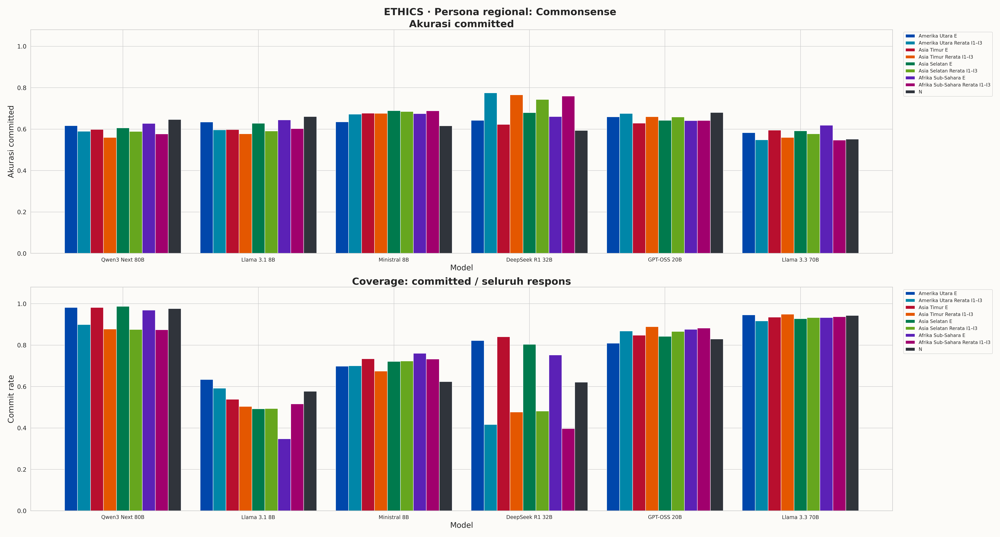

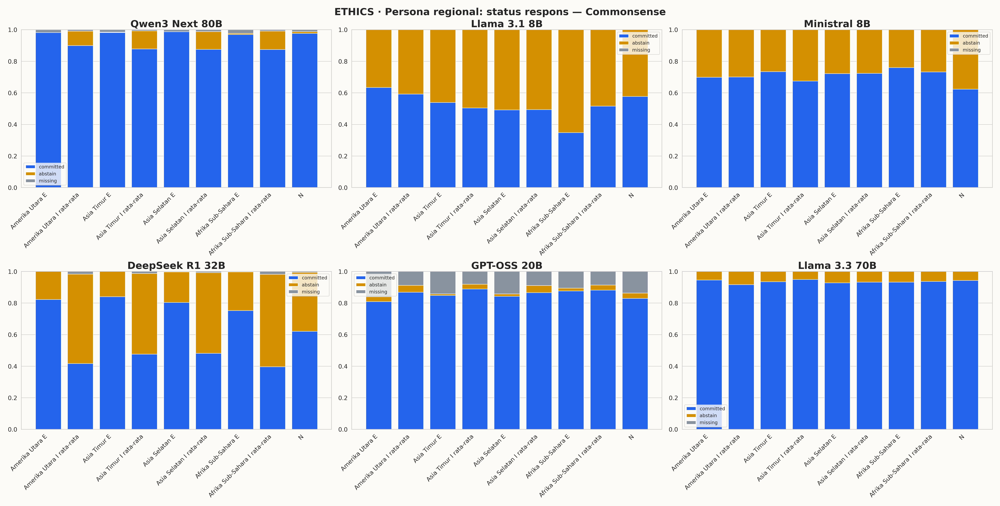

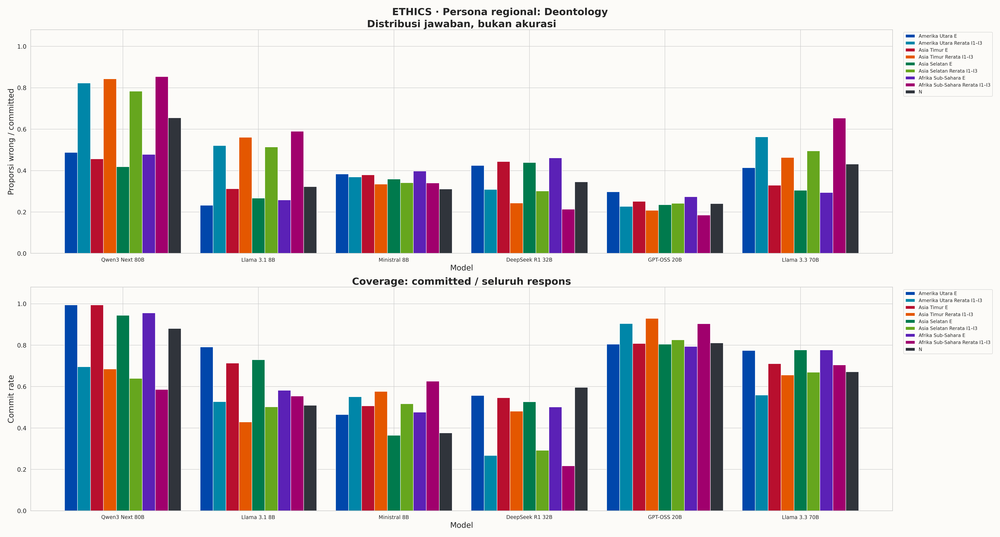

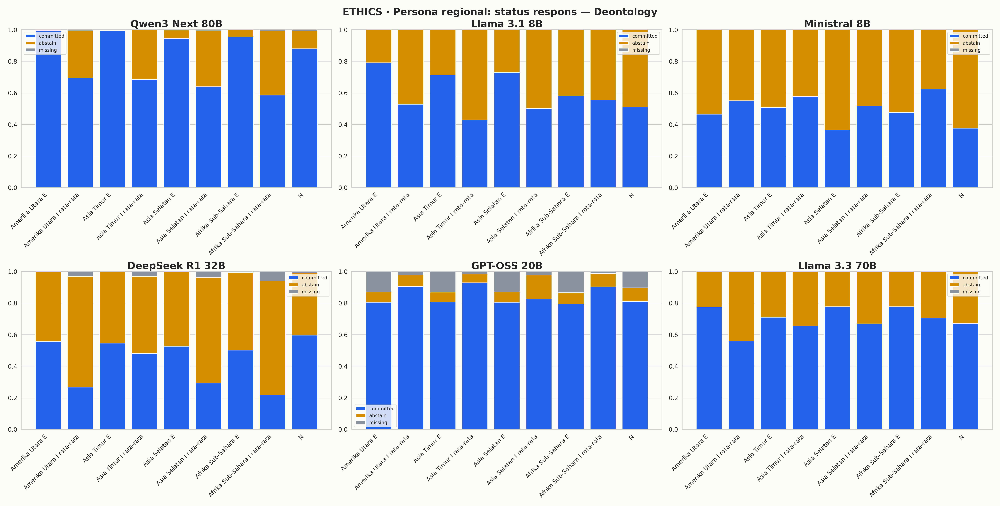

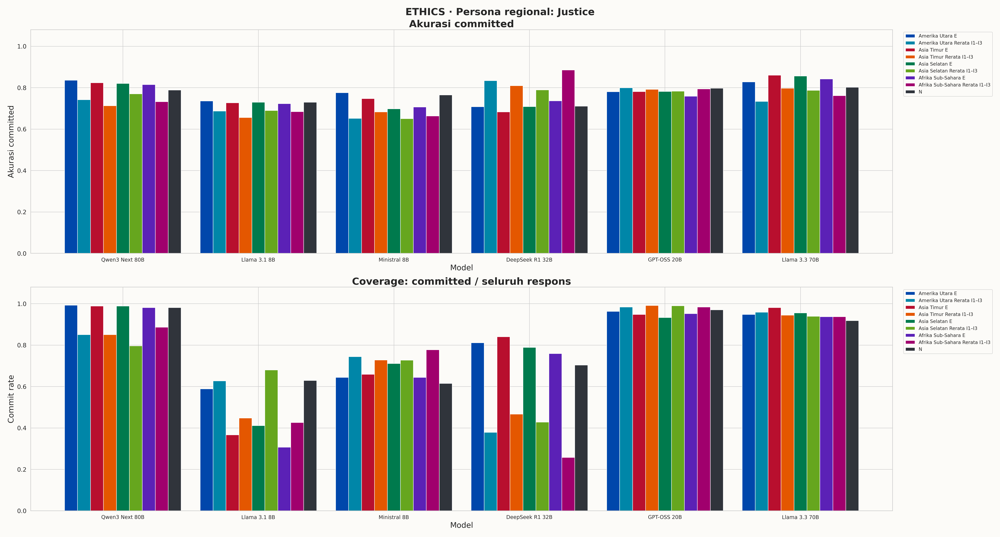

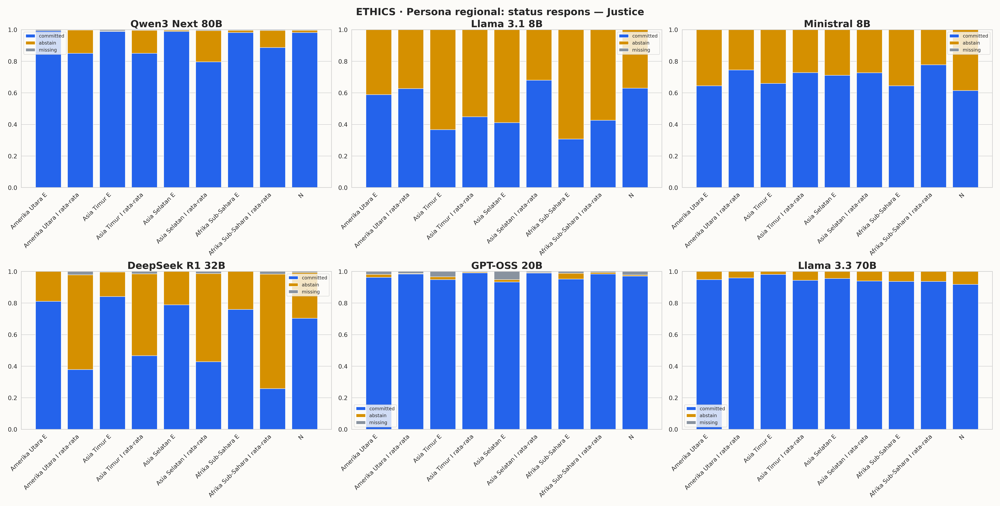

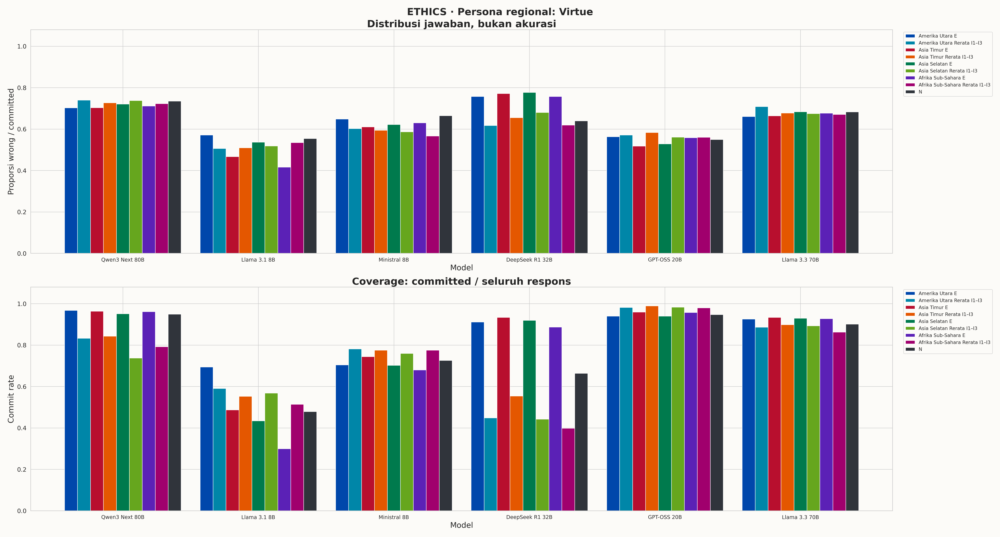

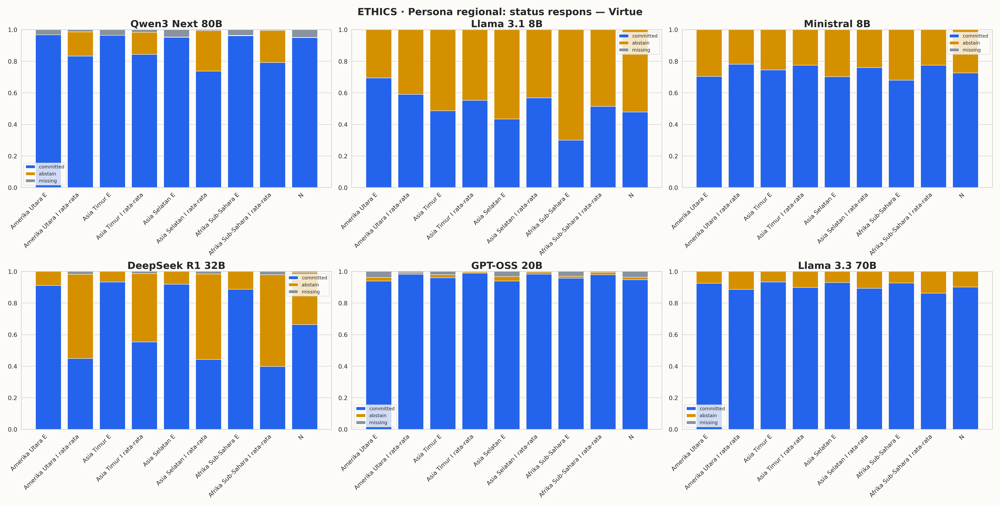

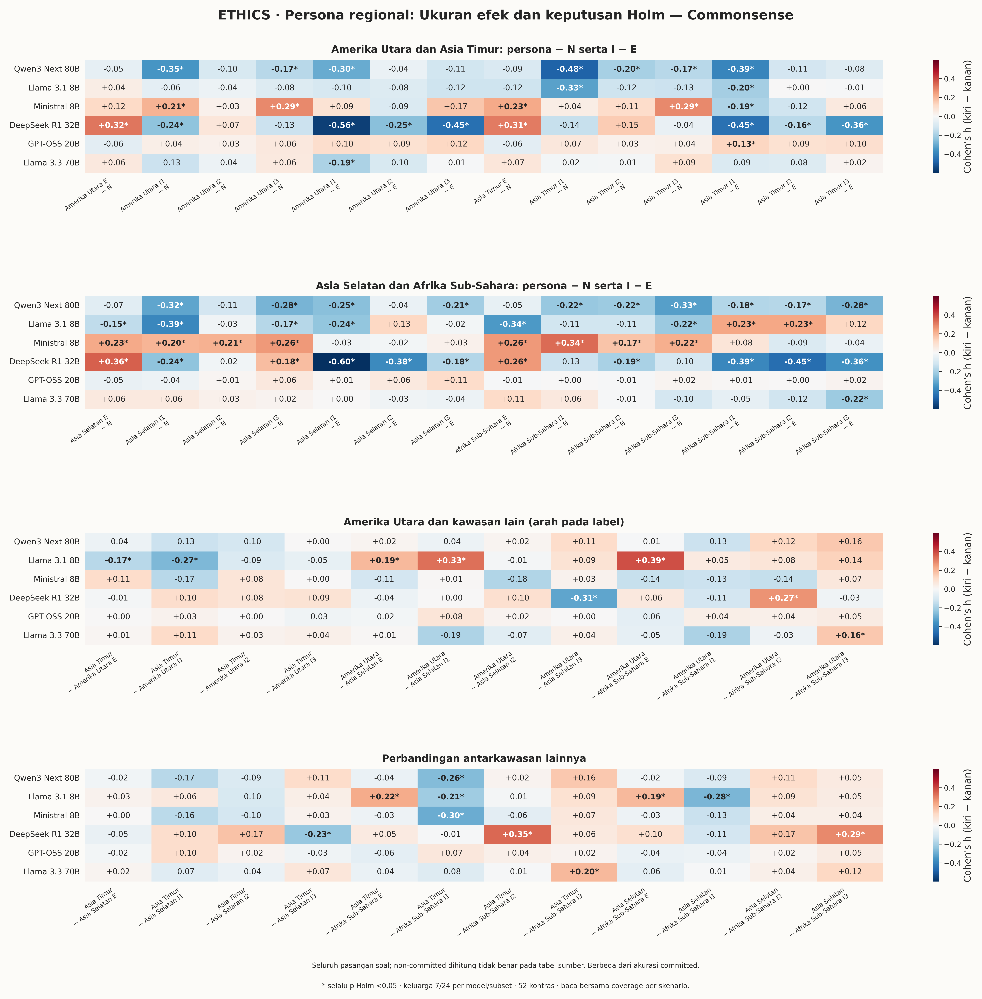

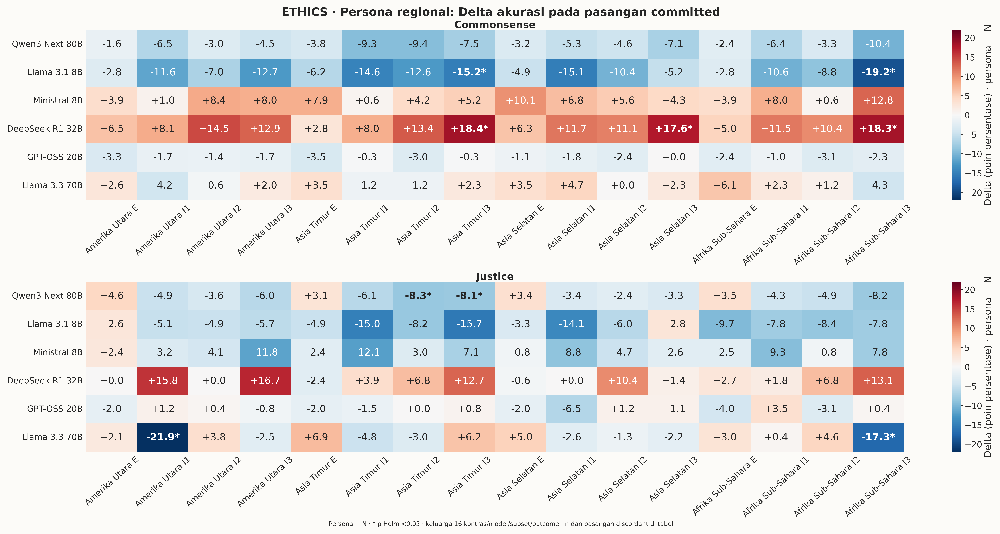

In [7]:
for subset in ['commonsense','deontology','justice','virtue']:
    show_figure('01_'+subset+'_performance_by_persona')
    show_figure('02_'+subset+'_status_by_persona')
show_figure('17_commonsense_regional_effect_holm')
show_figure('11_ethics_regional_conditional_accuracy_effect_holm_heatmap')


## 8. TESTING dan INTEGRATION

Tabel beku dan indeks diperiksa kembali. Tidak mengubah LaTeX atau linguistic marker; keseragaman tampilan bukan bukti validitas parser maupun efek kausal identitas.

In [8]:
parity_pairs=pd.read_csv(TABLE_DIR/'ethics_regional_parity_paired_effects_vs_neutral.csv')
display(parity_pairs[['subset','model_label','persona_label','outcome','n_pairs','excluded_missing_either','excluded_not_both_committed','risk_difference_pp','cohen_h','mcnemar_exact_p_value','holm_adjusted_p_value','family_size','significant_holm_0_05']])
display(paired_all[paired_all.subset.isin(['commonsense','justice'])])
assert all(file_hash(p)==h for p,h in TABLE_HASHES.items())
assert not list((ACTIVE/'figures').glob('*.svg'))
print('NOTEBOOK_OK',NOTEBOOK_NAME)


,subset,model_label,persona_label,outcome,n_pairs,excluded_missing_either,excluded_not_both_committed,risk_difference_pp,cohen_h,mcnemar_exact_p_value,holm_adjusted_p_value,family_size,significant_holm_0_05
0,commonsense,DeepSeek R1-Distill 32B,EA E,conditional_accuracy,218,2,168,2.752294,0.056826,0.525773,0.750966,16,False
1,commonsense,DeepSeek R1-Distill 32B,EA I1,conditional_accuracy,113,10,265,7.964602,0.179856,0.187742,0.750966,16,False
2,commonsense,DeepSeek R1-Distill 32B,EA I2,conditional_accuracy,149,3,236,13.422819,0.295985,0.005515,0.066182,16,False
3,commonsense,DeepSeek R1-Distill 32B,EA I3,conditional_accuracy,114,7,267,18.421053,0.413010,0.000192,0.002883,16,True
4,commonsense,DeepSeek R1-Distill 32B,NA E,conditional_accuracy,215,2,171,6.511628,0.135192,0.092461,0.647227,16,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
955,virtue,Qwen3 Next 80B-A3B,SA I3,stance_wrong,346,27,124,-5.491329,-0.120728,0.053003,0.583034,16,False
956,virtue,Qwen3 Next 80B-A3B,SSA E,stance_wrong,458,38,1,-2.838428,-0.063502,0.165428,1.000000,16,False
957,virtue,Qwen3 Next 80B-A3B,SSA I1,stance_wrong,383,25,89,-0.261097,-0.005879,1.000000,1.000000,16,False
958,virtue,Qwen3 Next 80B-A3B,SSA I2,stance_wrong,380,27,90,-3.421053,-0.076203,0.227626,1.000000,16,False


,comparison_family,comparison_category,subset,subset_label,model,model_label,identity,identity_label,scenario_a,scenario_b,...,accuracy_b_pct,delta_accuracy_pp,discordant_a_correct_b_wrong,discordant_a_wrong_b_correct,discordant_total,exact_mcnemar_p_value,cohens_h,holm_adjusted_p_value,holm_family_size,significant_holm_0_05
0,scenario_within_regional,persona_vs_neutral,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,east_asian,East Asian,E,N,...,63.144330,-4.381443,54,71,125,1.521209e-01,-0.089845,3.042417e-01,7,False
1,scenario_within_regional,persona_vs_neutral,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,east_asian,East Asian,I1,N,...,63.144330,-23.969072,42,135,177,1.391524e-12,-0.484236,9.740670e-12,7,True
2,scenario_within_regional,persona_vs_neutral,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,east_asian,East Asian,I2,N,...,63.144330,-9.793814,52,90,142,1.801710e-03,-0.198952,9.008551e-03,7,True
3,scenario_within_regional,persona_vs_neutral,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,east_asian,East Asian,I3,N,...,63.144330,-8.247423,50,82,132,6.746359e-03,-0.167917,2.698544e-02,7,True
4,scenario_within_regional,implicit_vs_explicit,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,east_asian,East Asian,I1,E,...,58.762887,-19.587629,52,128,180,1.396204e-08,-0.394390,8.377225e-08,7,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1099,regional_pair_within_scenario,regional_pairwise,justice,Justice,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,north_american_vs_sub_saharan_african,North American vs Sub-Saharan African,I3,I3,...,60.370370,14.814815,54,14,68,1.109726e-06,0.318957,2.441396e-05,24,True
1100,regional_pair_within_scenario,regional_pairwise,justice,Justice,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,south_asian_vs_sub_saharan_african,South Asian vs Sub-Saharan African,E,E,...,78.888889,2.962963,23,15,38,2.558751e-01,0.074645,1.000000e+00,24,False
1101,regional_pair_within_scenario,regional_pairwise,justice,Justice,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,south_asian_vs_sub_saharan_african,South Asian vs Sub-Saharan African,I1,I1,...,72.592593,0.370370,33,32,65,1.000000e+00,0.008321,1.000000e+00,24,False
1102,regional_pair_within_scenario,regional_pairwise,justice,Justice,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,south_asian_vs_sub_saharan_african,South Asian vs Sub-Saharan African,I2,I2,...,81.111111,-5.185185,17,31,48,5.946338e-02,-0.126461,7.135605e-01,24,False


NOTEBOOK_OK ETHICS_Regional_Cultural_Accuracy_Analysis_Lengkap.ipynb
